# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import KFold

wine_data = pd.read_csv('winequality-red.csv', sep=';')

wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
wine_data.info()

NameError: name 'wine_data' is not defined

In [ ]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level? 

In [4]:
wine_data['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

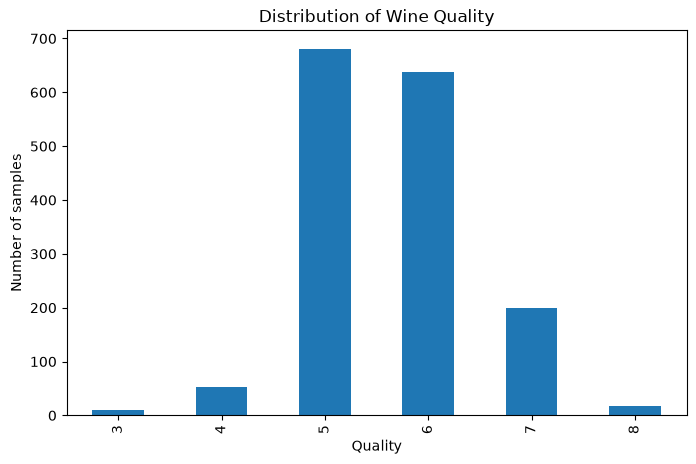

In [6]:
wine_data['quality'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.xlabel('Quality')
plt.ylabel('Number of samples')
plt.title('Distribution of Wine Quality')
plt.show()

### 3. What is the average value of each feature (column) in each `quality` score level? 

In [7]:
wine_data.groupby('quality').mean()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094
5,8.167254,0.577041,0.243686,2.528855,0.092736,16.983847,56.513950,0.997104,3.304949,0.620969,9.899706
6,8.347179,0.497484,0.273824,2.477194,0.084956,15.711599,40.869906,0.996615,3.318072,0.675329,10.629519
7,8.872362,0.403920,0.375176,2.720603,0.076588,14.045226,35.020101,0.996104,3.290754,0.741256,11.465913
8,8.566667,0.423333,0.391111,2.577778,0.068444,13.277778,33.444444,0.995212,3.267222,0.767778,12.094444


### 4. What is the median value of each feature (column) in each `quality` score level? 

In [8]:
wine_data.groupby('quality').median()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.50,0.845,0.035,2.1,0.0905,6.0,15.0,0.997565,3.39,0.545,9.925
4,7.50,0.670,0.090,2.1,0.0800,11.0,26.0,0.996500,3.37,0.560,10.000
5,7.80,0.580,0.230,2.2,0.0810,15.0,47.0,0.997000,3.30,0.580,9.700
6,7.90,0.490,0.260,2.2,0.0780,14.0,35.0,0.996560,3.32,0.640,10.500
7,8.80,0.370,0.400,2.3,0.0730,11.0,27.0,0.995770,3.28,0.740,11.500
8,8.25,0.370,0.420,2.1,0.0705,7.5,21.5,0.994940,3.23,0.740,12.150


### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

### 6. Create correlation matrix between all variables.

In [9]:
correlation_matrix = wine_data.corr()

correlation_matrix

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


### 7. Plot heatmap to see correlations.

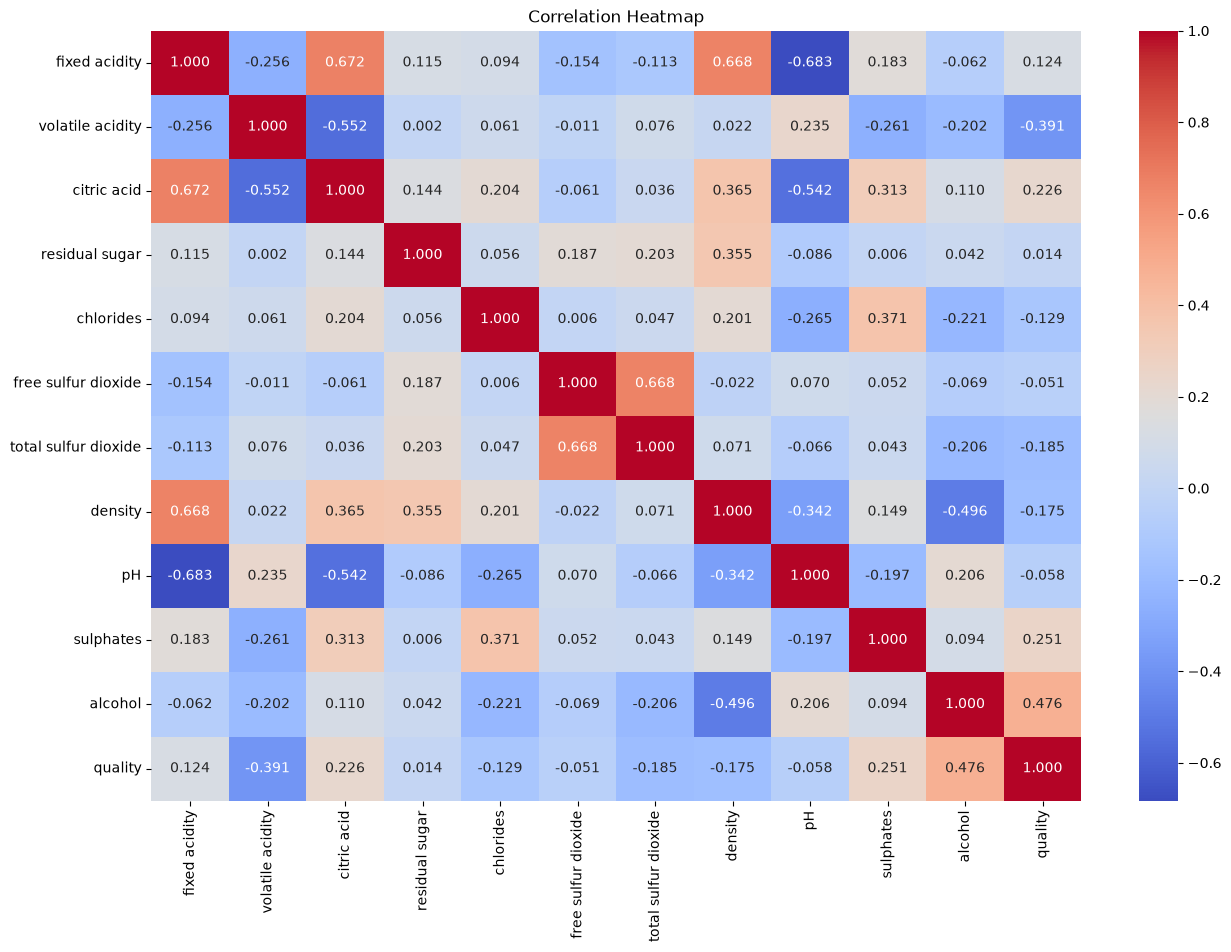

In [ ]:
plt.figure(figsize=(15, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f'
)
plt.title('Correlation Heatmap')
plt.show()

### 8. Identify potential outliers in `alcohol` using the IQR rule. Flag values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

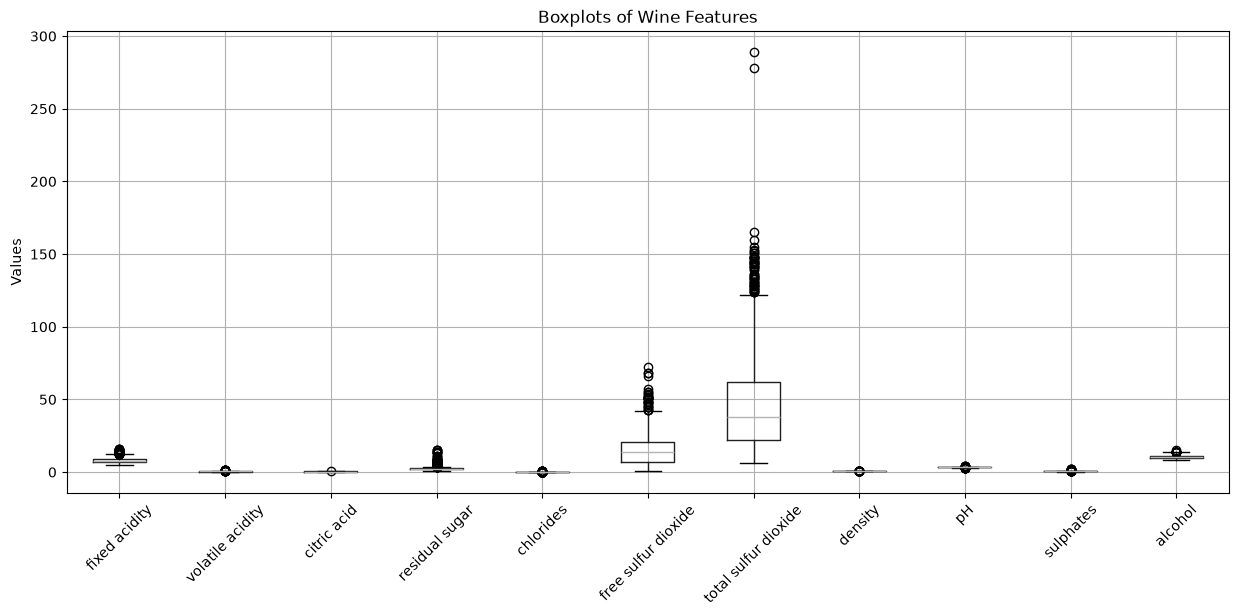

In [ ]:
plt.figure(figsize=(15, 6))
wine_data.drop(columns=['quality']).boxplot()
plt.title('Boxplots of Wine Features')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.show()

### 10. Plot boxplot of Ph for each quality type.

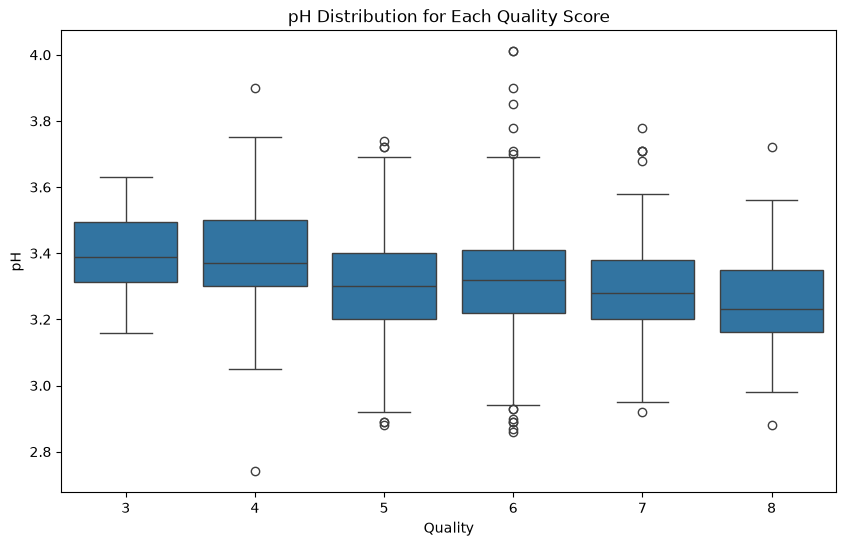

In [5]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=wine_data,
    x='quality',
    y='pH'
)
plt.title('pH Distribution for Each Quality Score')
plt.xlabel('Quality')
plt.ylabel('pH')
plt.show()

### 11. Plot a scatter plot of `quality` against the feature with the strongest correlation to it. Does alcohol content appear associated with wine quality?

### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

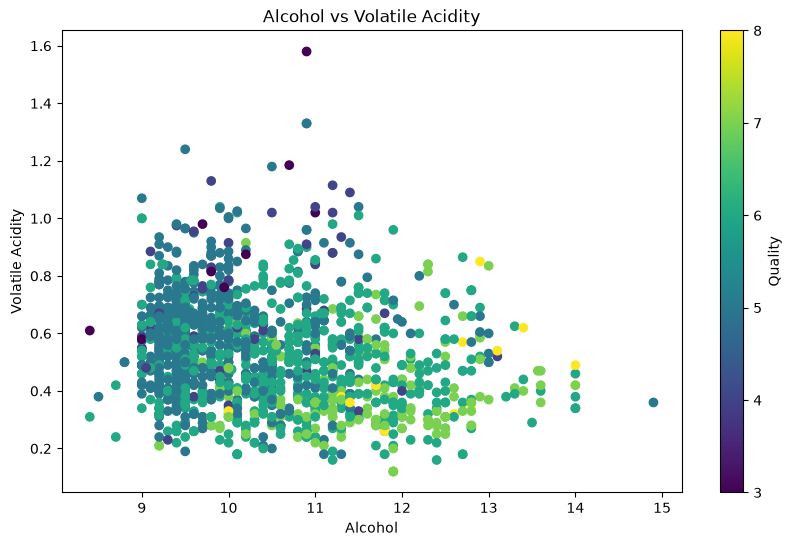

In [6]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    wine_data['alcohol'],
    wine_data['volatile acidity'],
    c=wine_data['quality'],
    cmap='viridis'
)
plt.xlabel('Alcohol')
plt.ylabel('Volatile Acidity')
plt.title('Alcohol vs Volatile Acidity')
plt.colorbar(scatter, label='Quality')
plt.show()

### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

### 14. Create two new features:
- Sulfur dioxide ratio (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [7]:
wine_data['sulfur dioxide ratio'] = (
    wine_data['free sulfur dioxide'] /
    wine_data['total sulfur dioxide']
)
wine_data['total acidity'] = (
    wine_data['fixed acidity'] +
    wine_data['volatile acidity'] +
    wine_data['citric acid']
)
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sulfur dioxide ratio,total acidity
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.323529,8.10
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0.373134,8.68
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0.277778,8.60
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0.283333,12.04
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.323529,8.10


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [8]:
dates = pd.date_range(
    start='2026-11-03',
    periods=7,
    freq='D'
)
date_data = pd.DataFrame({
    'date': dates
})
date_data['dayofweek'] = date_data['date'].dt.dayofweek
date_data['is_weekend'] = (
    date_data['dayofweek'] >= 5
)
date_data

C:\Users\m.babics\AppData\Local\Temp\ipykernel_8436\771757733.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  date_data['dayofweek'] = date_data['date'].dt.dayofweek


,date,dayofweek,is_weekend
0,2026-11-03,1,False
1,2026-11-04,2,False
2,2026-11-05,3,False
3,2026-11-06,4,False
4,2026-11-07,5,True
5,2026-11-08,6,True
6,2026-11-09,0,False
